# Завдання 4. Попіксельні операції: яскравість, негатив і поріг
Лекція 2

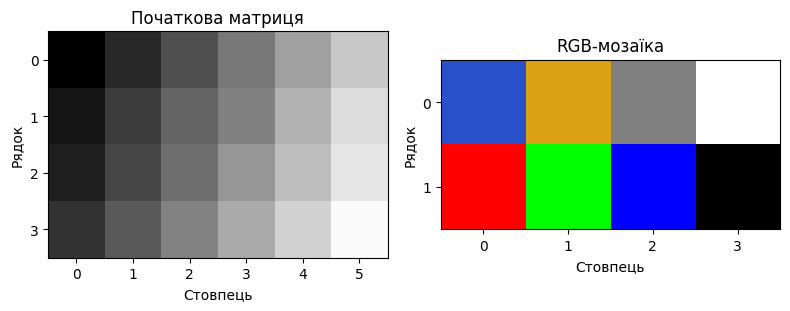

In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = np.array([
    [ 0, 40,  80, 120, 160, 200],
    [20, 60, 100, 128, 180, 220],
    [30, 70, 110, 150, 190, 230],
    [50, 90, 130, 170, 210, 250]
], dtype=np.uint8)

RGB = np.array([
    [[ 40,  80, 200], [220, 160,  20], [128, 128, 128], [255, 255, 255]],
    [[255,   0,   0], [  0, 255,   0], [  0,   0, 255], [  0,   0,   0]]
], dtype=np.uint8)

def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 3))
    for ax, (data, title) in zip(np.atleast_1d(axes), items):
        if data.ndim == 2:
            ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                      interpolation="nearest", origin="upper")
        else:
            ax.imshow(data, interpolation="nearest", origin="upper")
        ax.set_xticks(range(data.shape[1]))
        ax.set_yticks(range(data.shape[0]))
        ax.set_title(title)
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
    plt.tight_layout()
    plt.show()

# Спочатку обмежуємо діапазон, потім округлюємо й повертаємо uint8.
def to_uint8(values):
    return np.rint(np.clip(values, 0, 255)).astype(np.uint8)

show_images([(G, "Початкова матриця"), (RGB, "RGB-мозаїка")])

У матриці G значення 0 - піксель (0, 0); 128 - (1, 3); 250 - (3, 5).

## Зміна яскравості
### Ручний розрахунок для k = 40
| p | p + 40 (до обмеження) | Кінцеве значення |
|---|---|---|
| 0 | 40 | 40 |
| 128 | 168 | 168 |
| 250 | 290 | 255 |

_Перевірте розрахунок самі._

Форма й тип результату: (4, 6) uint8
,Значень нижче 0 до обмеження: 0
,Значень вище 255 до обмеження: 3
,(0, 0) початкове = 0 до обмеження = 40 результат = 40
,(1, 3) початкове = 128 до обмеження = 168 результат = 168
,(3, 5) початкове = 250 до обмеження = 290 результат = 255


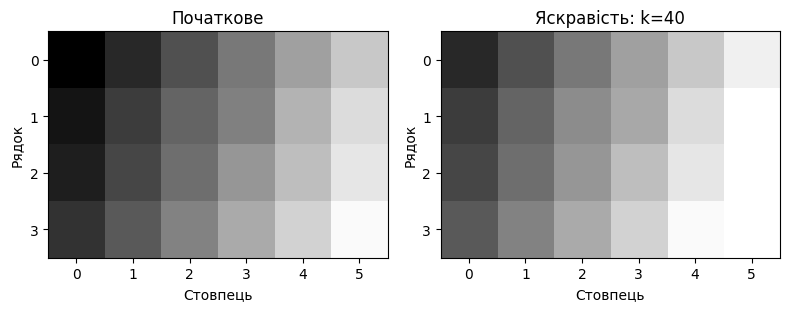

In [2]:
# Змінюйте k: -60, 0, 40, 100.
k = 40

raw = G.astype(np.int16) + k
bright = to_uint8(raw)

print("Форма й тип результату:", bright.shape, bright.dtype)
print("Значень нижче 0 до обмеження:", np.count_nonzero(raw < 0))
print("Значень вище 255 до обмеження:", np.count_nonzero(raw > 255))
for row, col in [(0, 0), (1, 3), (3, 5)]:
    print(
        (row, col), "початкове =", G[row, col],
        "до обмеження =", raw[row, col],
        "результат =", bright[row, col]
    )

show_images([(G, "Початкове"), (bright, f"Яскравість: k={k}")])

In [3]:
# Усі чотири запуски для таблиці (кожного разу з початкової G).
for k_ in (-60, 0, 40, 100):
    raw_ = G.astype(np.int16) + k_
    b_ = to_uint8(raw_)
    print(f"k={k_:4d}: p=0 -> {b_[0,0]} (до clip {raw_[0,0]}), "
          f"p=128 -> {b_[1,3]} (до clip {raw_[1,3]}), "
          f"p=250 -> {b_[3,5]} (до clip {raw_[3,5]}), "
          f"<0: {np.count_nonzero(raw_ < 0)}, >255: {np.count_nonzero(raw_ > 255)}")

k= -60: p=0 -> 0 (до clip -60), p=128 -> 68 (до clip 68), p=250 -> 190 (до clip 190), <0: 5, >255: 0
,k=   0: p=0 -> 0 (до clip 0), p=128 -> 128 (до clip 128), p=250 -> 250 (до clip 250), <0: 0, >255: 0
,k=  40: p=0 -> 40 (до clip 40), p=128 -> 168 (до clip 168), p=250 -> 255 (до clip 290), <0: 0, >255: 3
,k= 100: p=0 -> 100 (до clip 100), p=128 -> 228 (до clip 228), p=250 -> 255 (до clip 350), <0: 0, >255: 9


### Таблиця 1
| k | Прогноз зміни зображення | p=0 | p=128 | p=250 | Значень < 0 до clip | Значень > 255 до clip | Що спостерігали |
|---|---|---|---|---|---|---|---|
| -60 | Картинка стане рівномірно темно-сірою, дуже світлі пікселі трохи приглушаться. | 0 (до clip: -60) | 68 (до clip: 68) | 190 (до clip: 190) | 5 | 0 | Усе темнішає на 60. П'ять найтемніших пікселів (0, 20, 30, 40, 50) обрізаються до 0, тому темний кут стає однорідно чорним. Решта зберігає різницю між собою. |
| 0 | Зображення взагалі не зміниться, бо додаємо нуль, тож усі пікселі залишаться на своїх місцях без зсувів. | 0 (до clip: 0) | 128 (до clip: 128) | 250 (до clip: 250) | 0 | 0 | Зображення не змінюється. |
| 40 | Картинка стане помітно світлішою, нічого особливого: найтемніші трохи посвітлішають, а найсвітліші впруться в стелю 255 і трохи злиються, хоча більшість пікселів нормально зміститься. | 40 (до clip: 40) | 168 (до clip: 168) | 255 (до clip: 290) | 0 | 3 | Зображення світлішає. Три найсвітліші пікселі (220, 230, 250) стають 255 і зливаються. |
| 100 | Усе стане випаленим до чисто білого, бо значення «залипнуть» на максимальній межі. | 100 (до clip: 100) | 228 (до clip: 228) | 255 (до clip: 350) | 0 | 9 | Зображення сильно світле. Дев'ять пікселів стають 255, тобто світла частина картинки зливається в чисто білу. Темні пікселі лишаються різними. |

## Чому додавання в uint8 може зіпсувати зображення
**Прогноз для 210 і 250:** `G + np.uint8(40)` для 250 зупиниться на 255, бо `uint8` не дає переходити межу (максимум - білий). Обчислення в `int16` з `clip` дасть 290, яке обрізається до 255.

Останній рядок оригіналу: [ 50  90 130 170 210 250]
,Додавання в uint8: [ 90 130 170 210 250  34]
,З обмеженням діапазону: [ 90 130 170 210 250 255]
,Пікселів, які не відновилися: 3


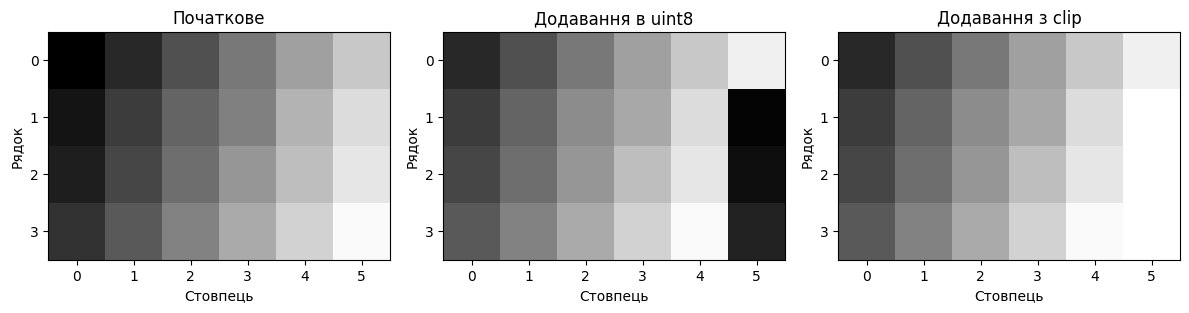

In [4]:
# Обидва операнди мають тип uint8: результат може переповнитися.
unsafe = G + np.uint8(40)
safe = to_uint8(G.astype(np.int16) + 40)

print("Останній рядок оригіналу:", G[-1])
print("Додавання в uint8:", unsafe[-1])
print("З обмеженням діапазону:", safe[-1])

# Спроба скасувати додавання після збереження результату в uint8.
restored_brightness = to_uint8(safe.astype(np.int16) - 40)
lost_pixels = np.count_nonzero(restored_brightness != G)
print("Пікселів, які не відновилися:", lost_pixels)

show_images([
    (G, "Початкове"),
    (unsafe, "Додавання в uint8"),
    (safe, "Додавання з clip")
])

### Результати
**Що вийшло насправді (прогноз для `uint8` не справдився):** `uint8` не зупиняється на 255, а переходить через межу за модулем 256, тому для 250 отримали 34, а не 255. Прогноз для `int16` з `clip` справдився.

Останній рядок оригіналу: `[50, 90, 130, 170, 210, 250]`.
- Додавання в `uint8`: `[90, 130, 170, 210, 250, 34]`. Для 210 вийшло 250, а для 250 вийшло **34**, бо 250 + 40 = 290, а в `uint8` результат береться за модулем 256: 290 − 256 = 34.
- З обмеженням діапазону: `[90, 130, 170, 210, 250, 255]`. Для 250 вийшло 255, бо 290 > 255 і clip обрізає його.
- Не відновилося **3** пікселі (у G це значення 220, 230 і 250). Для них 255 після clip замінило значення 260, 270 і 290, тож віднімання 40 дає 215, а не початкові 220, 230, 250. Інформація про те, наскільки значення перевищило 255, втрачена.

## Негатив зображення
### Ручний розрахунок 255 − p
| p | 255 − p |
|---|---|
| 0 | 255 |
| 128 | 127 |
| 250 | 5 |

Подвійний негатив відновив оригінал: True


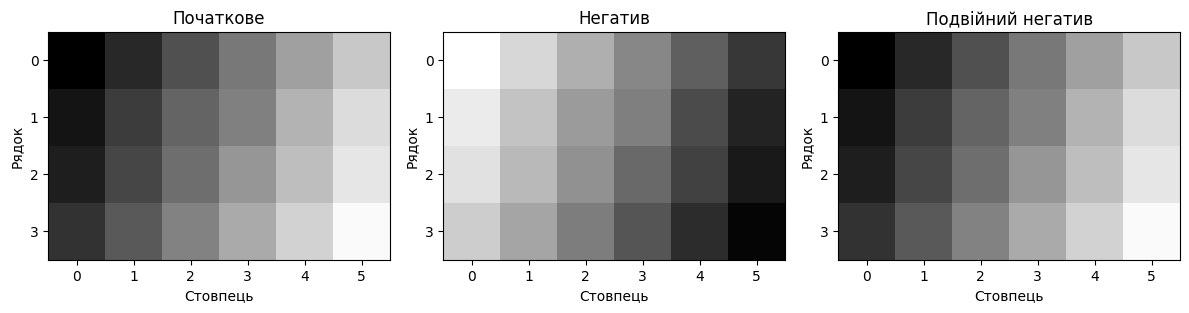

In [5]:
negative = np.uint8(255) - G
restored_negative = np.uint8(255) - negative

print("Подвійний негатив відновив оригінал:",
      np.array_equal(G, restored_negative))

show_images([
    (G, "Початкове"),
    (negative, "Негатив"),
    (restored_negative, "Подвійний негатив")
])

Подвійний негатив відновлює оригінал точно: 255 − (255 − p) = p, а всі проміжні значення лежать у діапазоні 0–255, тож нічого не обрізається. Додавання з clip цієї властивості не має, бо після обрізання кілька різних початкових значень стають однаковими (255).

## Порогове зображення
**Прогноз:** чим вищий поріг, тим більше білих пікселів залишиться (планка яскравості для виділення вища). Для G[1, 3] = 128 при порозі 128 і `G > threshold` піксель буде білим, бо значення рівні. При найвищому порозі зникнуть сірі фонові деталі, залишаться лише найсвітліші.

Поріг: 128
,Білих пікселів: 11
,Частка білих пікселів: 0.4583333333333333
,Піксель (1, 3): до = 128 після = 0


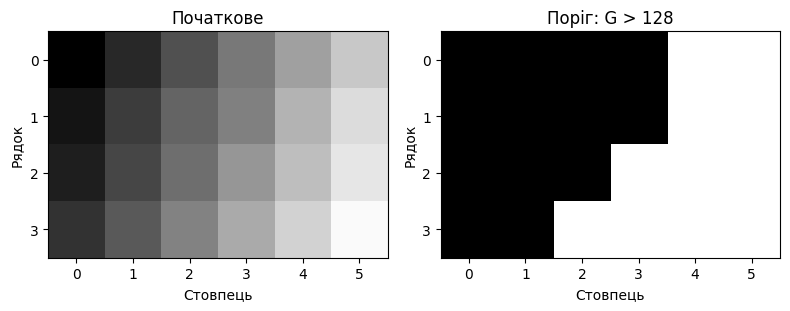

In [6]:
# Змінюйте threshold: 64, 128, 192.
threshold = 128
binary = np.where(G > threshold, 255, 0).astype(np.uint8)

white_count = np.count_nonzero(binary == 255)
print("Поріг:", threshold)
print("Білих пікселів:", white_count)
print("Частка білих пікселів:", white_count / binary.size)
print("Піксель (1, 3): до =", G[1, 3], "після =", binary[1, 3])

show_images([(G, "Початкове"), (binary, f"Поріг: G > {threshold}")])

Поріг 64: білих 18, частка 0.7500
,Поріг 128: білих 11, частка 0.4583
,Поріг 192: білих 5, частка 0.2083
,G > 128: білих 11 , G[1,3] -> 0
,G >= 128: білих 12 , G[1,3] -> 255


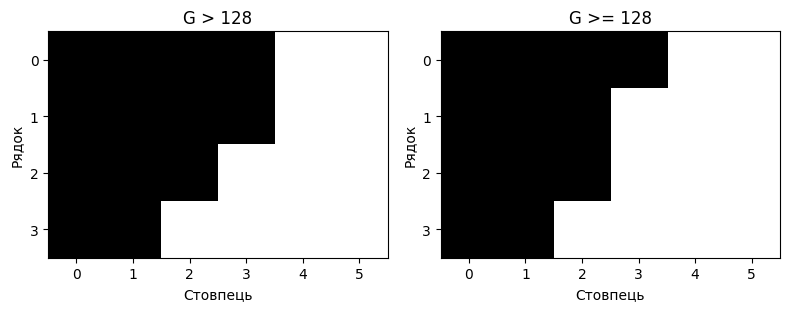

In [7]:
for th in (64, 128, 192):
    b_ = np.where(G > th, 255, 0).astype(np.uint8)
    n_ = np.count_nonzero(b_ == 255)
    print(f"Поріг {th}: білих {n_}, частка {n_ / b_.size:.4f}")

# Порівняння > та >= лише для порога 128.
b_gt = np.where(G > 128, 255, 0).astype(np.uint8)
b_ge = np.where(G >= 128, 255, 0).astype(np.uint8)
print("G > 128: білих", np.count_nonzero(b_gt == 255), ", G[1,3] ->", b_gt[1, 3])
print("G >= 128: білих", np.count_nonzero(b_ge == 255), ", G[1,3] ->", b_ge[1, 3])
show_images([(b_gt, "G > 128"), (b_ge, "G >= 128")])

### Таблиця 2
| Поріг | Прогноз зміни кількості білих | Білих пікселів | Частка білих | Що стало помітнішим або зникло |
|---|---|---|---|---|
| 64 | див. прогноз вище | 18 | 18/24 = 0.7500 | Більшість білі, чорними лишаються лише найтемніші (значення до 64). |
| 128 | див. прогноз вище | 11 | 11/24 = 0.4583 | Приблизно половина на половину. |
| 192 | див. прогноз вище | 5 | 5/24 = 0.2083 | Білими лишаються лише найсвітліші пікселі (200, 210, 220, 230, 250). |

**Що вийшло насправді (прогноз не справдився):** при вищому порозі білих пікселів стає **менше** (18 → 11 → 5), а не більше: білим стає лише піксель, що перевищує поріг, а чим вищий поріг, тим менше таких. Піксель G[1, 3] = 128 при `>` вийшов **чорним**, бо 128 > 128 хибно (рівність умови не задовольняє). Частина про те, що при найвищому порозі лишаються найсвітліші деталі, справдилась.

### Порівняння `>` і `>=` (поріг 128)
- `G > 128`: піксель G[1, 3] = 128 стає **чорним (0)**, білих пікселів — **11**.
- `G >= 128`: той самий піксель стає **білим (255)**, білих пікселів — **12**.
- Різниця: на 1 піксель, лише для значення, що дорівнює порогу. Після порівняння оператор `>` повернуто.

Результат містить лише 0 і 255, але зберігається в `uint8`, тобто кожен піксель займає один байт.

## Окремі коефіцієнти для RGB-каналів
**Прогноз:** якщо збільшити R і G у 1.5 раза, а B зменшити, баланс зсунеться до жовтого/помаранчевого. Сірий піксель перестане бути сірим, бо канали множаться на різні числа. Синя складова 200 × 1.5 = 300 обріжеться до 255.

Форма RGB: (2, 4, 3)
,Форма коефіцієнтів: (3,)
,Форма результату: (2, 4, 3)
,Компонент понад 255 до обмеження: 3
,(0, 0) RGB до = [ 40  80 200] до обмеження = [ 60.  80. 200.] RGB після = [ 60  80 200]
,(0, 1) RGB до = [220 160  20] до обмеження = [330. 160.  20.] RGB після = [255 160  20]
,(0, 2) RGB до = [128 128 128] до обмеження = [192. 128. 128.] RGB після = [192 128 128]


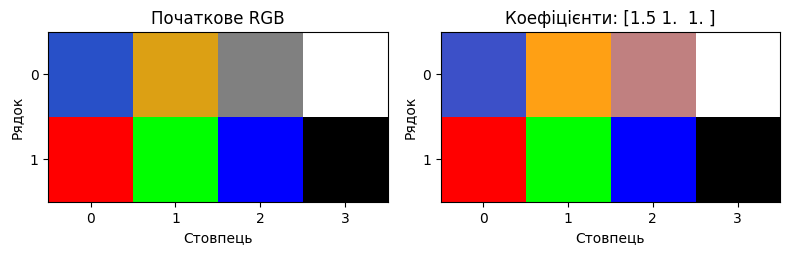

In [8]:
# Змінюйте gains: (1,1,1), (1.5,1,1), (1,0.5,1), (1,1,0).
gains = np.array([1.5, 1.0, 1.0])

if gains.shape != (3,) or not np.all(np.isfinite(gains)) or np.any(gains < 0):
    raise ValueError("Потрібні три скінченні невід'ємні коефіцієнти")

raw_rgb = RGB.astype(np.float64) * gains
scaled_rgb = to_uint8(raw_rgb)

print("Форма RGB:", RGB.shape)
print("Форма коефіцієнтів:", gains.shape)
print("Форма результату:", scaled_rgb.shape)
print("Компонент понад 255 до обмеження:",
      np.count_nonzero(raw_rgb > 255))
for row, col in [(0, 0), (0, 1), (0, 2)]:
    print(
        (row, col), "RGB до =", RGB[row, col],
        "до обмеження =", raw_rgb[row, col],
        "RGB після =", scaled_rgb[row, col]
    )

show_images([(RGB, "Початкове RGB"), (scaled_rgb, f"Коефіцієнти: {gains}")])

In [9]:
for g_ in [(1, 1, 1), (1.5, 1, 1), (1, 0.5, 1), (1, 1, 0)]:
    raw_ = RGB.astype(np.float64) * np.array(g_)
    s_ = to_uint8(raw_)
    print(g_, "RGB[0,0] ->", s_[0, 0], "| RGB[0,2] ->", s_[0, 2],
          "| >255:", np.count_nonzero(raw_ > 255))

(1, 1, 1) RGB[0,0] -> [ 40  80 200] | RGB[0,2] -> [128 128 128] | >255: 0
,(1.5, 1, 1) RGB[0,0] -> [ 60  80 200] | RGB[0,2] -> [192 128 128] | >255: 3
,(1, 0.5, 1) RGB[0,0] -> [ 40  40 200] | RGB[0,2] -> [128  64 128] | >255: 0
,(1, 1, 0) RGB[0,0] -> [40 80  0] | RGB[0,2] -> [128 128   0] | >255: 0


### Таблиця 3
| Коефіцієнти (R,G,B) | Прогноз RGB[0,0] | Фактичний RGB[0,0] | RGB сірого пікселя [0,2] | Компонент > 255 до clip | Що спостерігали |
|---|---|---|---|---|---|
| (1, 1, 1) | див. прогноз вище | [40, 80, 200] | [128, 128, 128] | 0 | Нічого не змінилося, сірий залишився сірим. |
| (1.5, 1, 1) | див. прогноз вище | [60, 80, 200] | [192, 128, 128] | 3 | Червоний компонент (R) збільшився в 1.5 раза; три значення R обрізалися до 255. Сірий піксель став червонуватим. |
| (1, 0.5, 1) | див. прогноз вище | [40, 40, 200] | [128, 64, 128] | 0 | Зелений компонент (G) зменшився вдвічі. Сірий піксель став пурпуровим. |
| (1, 1, 0) | див. прогноз вище | [40, 80, 0] | [128, 128, 0] | 0 | Синій компонент (B) обнулений. Сірий піксель став жовто-оливковим. |

**Що вийшло насправді:** прогноз стосувався іншого набору коефіцієнтів, ніж чотири запуски із завдання. У цих запусках синя складова 200 не множиться на 1.5, а обрізання до 255 відбувається для R при (1.5, 1, 1). Частина прогнозу про сірий піксель справдилась.

Сірий піксель RGB[0, 2] = [128, 128, 128] залишається сірим лише при (1, 1, 1). В інших трьох випадках канали множаться на різні коефіцієнти, тому R, G, B перестають бути рівними.

## Відповіді на питання
1. Операції діють на кожен піксель окремо за формулою, не змінюючи кількості рядків, стовпців і каналів, тому `shape` зберігається. Результати: `bright` - (4, 6), `uint8`; `negative` - (4, 6), `uint8`; `binary` - (4, 6), `uint8`; `scaled_rgb` - (2, 4, 3), `uint8`.
2. У `uint8` значення, що перевищує 255, не обрізається, а переходить через межу за модулем 256. Приклад із запуску: 250 + 40 = 290, у `uint8` це 290- 256 = **34**. Тобто найсвітліший піксель стає майже чорним. З clip отримуємо 255.
3. Негатив 255 - p взаємно однозначний і не виводить значення за межі 0-255, тож повторне застосування повертає p. Після додавання з clip значення 220, 230 і 250 стають однаковими 255, і за 255 уже не можна відновити початкове значення, тому відняти 40 не повертає оригінал (не відновилися 3 пікселі).
4. Для пікселя, що дорівнює порогу, `>` дає чорний, а `>=` - білий. Для G[1, 3] = 128 і порогу 128 кількість білих пікселів змінюється з 11 до 12.
5. Вектор `gains` форми (3,) вирівнюється по останній осі масиву (2, 4, 3), тобто NumPy застосовує його до каналів кожного з 8 пікселів, ніби повторюючи по рядках і стовпцях без створення копій. `RGB * gains` — поелементне множення (R на k_R, G на k_G, B на k_B), форма результату зберігається. Матричний добуток `@` комбінував би значення за правилом «рядок на стовпець», змішував би канали й давав би іншу форму.

## Висновок
Попіксельні операції застосовують одну формулу до всіх пікселів незалежно від сусідів, тому форма масиву не змінюється. Для арифметики з uint8 безпечний порядок такий: розширити тип, виконати обчислення, обмежити діапазон, округлити й повернути uint8, бо інакше значення переходять через межу за модулем 256 і світлі пікселі стають темними. Clip робить яскравість необоротною, а негатив оборотний, бо його результат ніколи не виходить за межі діапазону. У порогу вибір `>` чи `>=` змінює результат лише для пікселів, що дорівнюють порогу. Множення RGB на вектор коефіцієнтів змінює баланс каналів через broadcasting, але змінює й сірі пікселі, які перестають бути сірими.